# Imports

In [158]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial.distance import cdist
from pulp import *
import time
from IPython.display import clear_output, display

# Génération d'instances

In [ ]:
def verifier_inegalite_triangulaire(dist):
    n = len(dist)
    for i in range(n):
        for j in range(n):
            for k in range(n):
                if dist[i][j] > dist[i][k] + dist[k][j]:
                    return False
    return True

def generer_instance(n, x_max=500, y_max=500, seed=None):
    while True:
        if seed is not None:
            np.random.seed(seed)
        
        x_coords = np.random.randint(1, x_max, size=n)
        y_coords = np.random.randint(1, y_max, size=n)
        coords = np.column_stack((x_coords, y_coords))
        
        dist = np.round(cdist(coords, coords, metric='euclidean') * 100).astype(int)
        
        if verifier_inegalite_triangulaire(dist):
            return coords.tolist(), dist
        
        seed = None

# Résolution : PLNE, PPV, ACO

In [ ]:
def resoudre_tsp_plne(dist):
    n = len(dist)
    villes = range(n)
    prob = LpProblem("TSP", LpMinimize)
    
    x = LpVariable.dicts("x", (villes, villes), cat="Binary")
    p = LpVariable.dicts("p", range(1, n), lowBound=1, upBound=n - 1, cat="Continuous")
    
    prob += lpSum(dist[i][j] * x[i][j] for i in villes for j in villes if i != j)
    
    for i in villes:
        prob += lpSum(x[i][j] for j in villes if j != i) == 1
        prob += lpSum(x[j][i] for j in villes if j != i) == 1
    
    for i in range(1, n):
        for j in range(1, n):
            if i != j:
                prob += p[i] - p[j] + n * x[i][j] <= n - 1
    
    debut = time.time()
    prob.solve(PULP_CBC_CMD(msg=0))
    duree = time.time() - debut
    
    if LpStatus[prob.status] != "Optimal":
        return None, None, duree
    
    cout = value(prob.objective)
    tournee = [0]
    ville_courante = 0
    for _ in range(n - 1):
        for j in villes:
            if j != ville_courante and value(x[ville_courante][j]) > 0.5:
                tournee.append(j)
                ville_courante = j
                break
    
    return tournee, cout, duree

In [ ]:
def plus_proche_voisin(dist, ville_depart=0):
    n = len(dist)
    non_visitees = set(range(n)) - {ville_depart}
    tournee = [ville_depart]
    ville_courante = ville_depart
    cout = 0
    
    while non_visitees:
        ville_suivante = min(non_visitees, key=lambda v: dist[ville_courante][v])
        cout += dist[ville_courante][ville_suivante]
        tournee.append(ville_suivante)
        non_visitees.remove(ville_suivante)
        ville_courante = ville_suivante
    
    cout += dist[ville_courante][ville_depart]
    return tournee, cout

In [ ]:
def construire_tournee_fourmi(dist, pheromones, alpha, beta, ville_depart=0):
    n = len(dist)
    non_visitees = set(range(n)) - {ville_depart}
    tournee = [ville_depart]
    ville_courante = ville_depart
    cout = 0
    
    while non_visitees:
        candidates = list(non_visitees)
        scores = []
        for j in candidates:
            tau = pheromones[ville_courante][j] ** alpha
            eta = (1.0 / dist[ville_courante][j]) ** beta if dist[ville_courante][j] > 0 else 0
            scores.append(tau * eta)
        
        total = sum(scores)
        if total == 0:
            probabilites = [1.0 / len(candidates)] * len(candidates)
        else:
            probabilites = [s / total for s in scores]
        
        ville_suivante = np.random.choice(candidates, p=probabilites)
        cout += dist[ville_courante][ville_suivante]
        tournee.append(int(ville_suivante))
        non_visitees.remove(ville_suivante)
        ville_courante = ville_suivante
    
    cout += dist[ville_courante][ville_depart]
    return tournee, cout

In [ ]:
def resoudre_tsp_aco(dist, alpha=1.0, beta=3.0, rho=0.1,
                     nb_fourmis=None, nb_iterations=100,
                     seed=None, silencieux=False):
    if seed is not None:
        np.random.seed(seed)
    
    n = len(dist)
    if nb_fourmis is None:
        nb_fourmis = n
    
    _, cout_nn = plus_proche_voisin(dist)
    tau_0 = nb_fourmis / cout_nn
    pheromones = [[tau_0 for _ in range(n)] for _ in range(n)]
    
    meilleure_tournee = None
    meilleur_cout = float('inf')
    historique = []
    
    debut = time.time()
    
    for iteration in range(nb_iterations):
        tournees_iteration = []
        
        for _ in range(nb_fourmis):
            tournee, cout = construire_tournee_fourmi(dist, pheromones, alpha, beta)
            tournees_iteration.append((tournee, cout))
            
            if cout < meilleur_cout:
                meilleur_cout = cout
                meilleure_tournee = tournee
        
        for i in range(n):
            for j in range(n):
                pheromones[i][j] *= (1 - rho)
        
        for tournee, cout in tournees_iteration:
            depot = 1.0 / cout
            for k in range(len(tournee)):
                i = tournee[k]
                j = tournee[(k + 1) % len(tournee)]
                pheromones[i][j] += depot
                pheromones[j][i] += depot
        
        historique.append(meilleur_cout)
    
    duree = time.time() - debut
    
    if not silencieux:
        print(f"Coût ACO : {meilleur_cout:.2f}")
        print(f"Temps : {duree:.4f} s")
    
    return meilleure_tournee, meilleur_cout, duree, historique

# Module statistique

In [ ]:
def calculer_stats(couts, cout_opt):
    couts_arr = np.array(couts)
    ratios = couts_arr / cout_opt
    
    return {
        'ratios': ratios,
        'score_perf': np.mean(ratios),
        'score_perf_std': np.std(ratios),
        'moy_cout': np.mean(couts_arr),
        'std_cout': np.std(couts_arr)
    }

In [ ]:
def barre_progression(current, total, label="Progression"):
    pct = current / total * 100
    
    fig, ax = plt.subplots(figsize=(12, 1.5))
    ax.set_xlim(0, 100)
    ax.set_ylim(0, 1)
    
    rect_background = plt.Rectangle((0, 0.3), 100, 0.4, color='lightgray', linewidth=2, edgecolor='black')
    ax.add_patch(rect_background)
    
    rect_filled = plt.Rectangle((0, 0.3), pct, 0.4, color='steelblue', linewidth=2, edgecolor='steelblue')
    ax.add_patch(rect_filled)
    
    ax.text(50, 0.5, f'{label} : {pct:.1f}% ({current}/{total})', 
            ha='center', va='center', fontsize=14, fontweight='bold', color='white' if pct > 50 else 'black')
    
    ax.set_xticks([])
    ax.set_yticks([])
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.spines['left'].set_visible(False)
    
    plt.tight_layout()
    
    clear_output(wait=True)
    display(fig)
    plt.close()

In [ ]:
def etude_sensibilite(param_name, param_values, instances, optima,
                      fixed_params, n_exec=30, verbose=True):
    resultats = []
    n_instances = len(instances)
    n_param_vals = len(param_values)
    tous_ratios = {}
    
    total_iterations = n_param_vals * n_instances
    completed = 0
    
    for param_idx, param_val in enumerate(param_values):
        if verbose:
            print(f"\n{param_name} = {param_val}")
        
        stats_par_instance = []
        ratios_par_exec = []
        
        for idx_inst, (coords, dist) in enumerate(instances):
            n = len(dist)
            _, cout_opt = optima[idx_inst]
            
            couts_exec = []
            
            for exec_k in range(n_exec):
                params = fixed_params.copy()
                params[param_name] = param_val
                params['nb_fourmis'] = n
                params['silencieux'] = True
                
                _, cout, _, _ = resoudre_tsp_aco(dist, **params)
                couts_exec.append(cout)
            
            stats = calculer_stats(couts_exec, cout_opt)
            ratios_par_exec.extend(stats['ratios'])
            stats.pop('ratios')
            stats_par_instance.append(stats)
            
            completed += 1
            barre_progression(completed, total_iterations, f"Étude {param_name}")
        
        stat_agreg = {}
        for key in stats_par_instance[0].keys():
            values = [s[key] for s in stats_par_instance]
            stat_agreg[key + '_moy'] = np.mean(values)
        
        ratios_all = np.array(ratios_par_exec)
        stat_agreg['score_perf_min'] = np.min(ratios_all)
        stat_agreg['score_perf_max'] = np.max(ratios_all)
        stat_agreg['score_perf_median'] = np.median(ratios_all)
        
        min_ratio = stat_agreg['score_perf_min']
        max_ratio = stat_agreg['score_perf_max']
        mean_ratio = stat_agreg['score_perf_moy']
        
        if max_ratio > min_ratio:
            position_pct = (mean_ratio - min_ratio) / (max_ratio - min_ratio) * 100
        else:
            position_pct = 50.0
        
        stat_agreg['position_dans_plage_%'] = position_pct
        
        resultats.append({
            param_name: param_val,
            **stat_agreg
        })
        tous_ratios[param_val] = ratios_all
    
    return pd.DataFrame(resultats), tous_ratios

In [ ]:
def tracer_sensibilite(param_name, df, tous_ratios):
    fig, ax = plt.subplots(figsize=(10, 6))
    
    param_vals = df[param_name].values
    means = df['score_perf_moy'].values
    mins = df['score_perf_min'].values
    maxs = df['score_perf_max'].values
    
    ax.fill_between(param_vals, mins, maxs, alpha=0.3, color='steelblue', label='Plage [min, max]')
    ax.plot(param_vals, means, marker='o', linewidth=2.5, markersize=8, color='steelblue', label='Score moyen')
    ax.axhline(y=1.0, color='red', linestyle='--', linewidth=2, label='Optimum exact')
    
    ax.set_xlabel(f'{param_name.upper()}', fontsize=12, fontweight='bold')
    ax.set_ylabel('Score de performance (coût ACO / optimum)', fontsize=12, fontweight='bold')
    ax.set_title(f'Impact de {param_name} sur la qualité des solutions', fontsize=13, fontweight='bold')
    ax.legend(fontsize=11)
    ax.grid(True, alpha=0.3)
    ax.set_ylim([0.99, max(maxs) * 1.05])
    
    plt.tight_layout()
    plt.show()

In [ ]:
def afficher_resultats(param_name, df):
    df_display = df.copy()
    
    mapping_colonnes = {
        param_name: param_name.upper(),
        'score_perf_moy': 'Score moyen',
        'score_perf_median': 'Médiane',
        'score_perf_min': 'Min',
        'score_perf_max': 'Max',
        'position_dans_plage_%': 'Position (%)',
        'moy_cout_moy': 'Coût moyen'
    }
    
    colonnes_affichage = [param_name, 'score_perf_moy', 'score_perf_median', 
                          'score_perf_min', 'score_perf_max', 'position_dans_plage_%', 'moy_cout_moy']
    colonnes_valides = [c for c in colonnes_affichage if c in df_display.columns]
    
    df_display = df_display[colonnes_valides].copy()
    
    for col in colonnes_valides:
        if col != param_name:
            if col == 'position_dans_plage_%':
                df_display[col] = df_display[col].apply(lambda x: f"{x:.1f}%")
            else:
                df_display[col] = df_display[col].apply(lambda x: f"{x:.4f}")
    
    df_display = df_display.rename(columns=mapping_colonnes)
    
    def style_table(val):
        return 'text-align: center; padding: 8px; font-size: 11px;'
    
    styled = df_display.style\
        .set_properties(**{'text-align': 'center', 'padding': '10px', 'font-size': '12px', 'border': '1px solid #ddd'})\
        .set_table_styles([\
            {'selector': 'th', 'props': [('background-color', '#4472C4'), ('color', 'white'), ('font-weight', 'bold'), ('text-align', 'center'), ('padding', '12px'), ('font-size', '12px')]},\
            {'selector': 'td', 'props': [('text-align', 'center'), ('padding', '10px')]},\
            {'selector': 'tr:nth-child(odd)', 'props': [('background-color', '#f0f0f0')]},\
            {'selector': 'tr:nth-child(even)', 'props': [('background-color', '#ffffff')]}\
        ])
    
    display(styled)

def tracer_distribution(param_name, df, tous_ratios):
    n_params = len(df)
    fig, axes = plt.subplots(1, n_params, figsize=(4*n_params, 5))
    
    if n_params == 1:
        axes = [axes]
    
    for idx, (param_val, ax) in enumerate(zip(df[param_name].values, axes)):
        ratios = tous_ratios[param_val]
        
        ax.hist(ratios, bins=20, alpha=0.7, color='steelblue', edgecolor='black')
        
        mean_val = np.mean(ratios)
        median_val = np.median(ratios)
        min_val = np.min(ratios)
        max_val = np.max(ratios)
        
        ax.axvline(mean_val, color='orange', linestyle='--', linewidth=2, label=f'Moyenne: {mean_val:.4f}')
        ax.axvline(median_val, color='green', linestyle='--', linewidth=2, label=f'Médiane: {median_val:.4f}')
        ax.axvline(1.0, color='red', linestyle='-', linewidth=2, label='Optimum')
        
        position_pct = (mean_val - min_val) / (max_val - min_val) * 100
        
        ax.set_xlabel('Ratio (coût ACO / optimum)', fontsize=11, fontweight='bold')
        ax.set_ylabel('Fréquence', fontsize=11, fontweight='bold')
        ax.set_title(f'{param_name.upper()} = {param_val}\nPosition: {position_pct:.1f}% dans [min, max]', 
                     fontsize=11, fontweight='bold')
        ax.legend(fontsize=9)
        ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

In [ ]:
def multi_start_aco(dist, cout_opt, params_aco, n_runs=20):
    """Multi-start : lance ACO n_runs fois avec les mêmes paramètres fixes."""
    solutions = []
    temps_total = 0
    
    for run in range(n_runs):
        tournee, cout, duree, _ = resoudre_tsp_aco(dist, silencieux=True, **params_aco)
        solutions.append({
            'run': run + 1,
            'tournee': tournee,
            'cout': cout,
            'ratio': cout / cout_opt,
            'temps': duree
        })
        temps_total += duree
    
    df = pd.DataFrame(solutions)
    
    stats = {
        'meilleur_cout': df['cout'].min(),
        'pire_cout': df['cout'].max(),
        'cout_moyen': df['cout'].mean(),
        'cout_median': df['cout'].median(),
        'cout_std': df['cout'].std(),
        'ratio_moyen': df['ratio'].mean(),
        'ratio_min': df['ratio'].min(),
        'temps_total': temps_total
    }
    
    return df, stats

# Résolution

## Plan d'expérience

In [ ]:
N = 15                  # nombre de villes
N_INSTANCES = 5         # nombre d'instances à générer
N_EXECUTIONS = 30       # nombre d'exécutions par instance

print(f"Génération de {N_INSTANCES} instances de taille n={N}...")
instances = []
for i in range(N_INSTANCES):
    coords, dist = generer_instance(N, seed=i)
    instances.append((coords, dist))
    if (i + 1) % 5 == 0:
        print(f"  {i + 1}/{N_INSTANCES} générées")

print(f"\nCalcul des optimaux (PLNE)...")
optima = []
for i, (coords, dist) in enumerate(instances):
    tournee, cout, duree = resoudre_tsp_plne(dist)
    optima.append((tournee, cout))
    print(f"  Instance {i+1}/{N_INSTANCES} : optimum = {cout:.0f} ({duree:.2f}s)")

print(f"\nPrêt pour l'étude expérimentale.")

# Paramètres de l'étude
fixed_params = {
    'alpha': 1.0,
    'beta': 3,
    'rho': 0.1,
    'nb_iterations': 50
}

alpha_values = [0.5, 1.0, 1.5, 2.0]
beta_values = [1, 2, 3, 4, 5]
rho_values = [0.1, 0.2, 0.3, 0.4, 0.5]

Génération de 5 instances de taille n=15...
  5/5 générées

Calcul des optimaux (PLNE)...
  Instance 1/5 : optimum = 151183 (1.86s)
  Instance 2/5 : optimum = 174864 (0.70s)
  Instance 3/5 : optimum = 176063 (1.02s)
  Instance 4/5 : optimum = 148675 (1.90s)
  Instance 5/5 : optimum = 161843 (0.48s)

Prêt pour l'étude expérimentale.


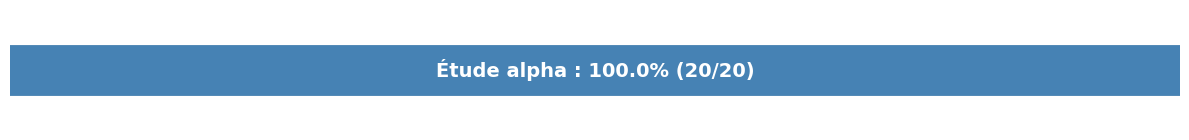


Résultats (alpha):



,ALPHA,Score moyen,Médiane,Min,Max,Position (%),Coût moyen
0,0.500000,1.0012,1.0000,1.0000,1.0324,3.6%,162704.4733
1,1.000000,1.0019,1.0000,1.0000,1.0553,3.5%,162823.0267
2,1.500000,1.0071,1.0000,1.0000,1.0868,8.1%,163602.8867
3,2.000000,1.0112,1.0033,1.0000,1.1000,11.2%,164266.0267


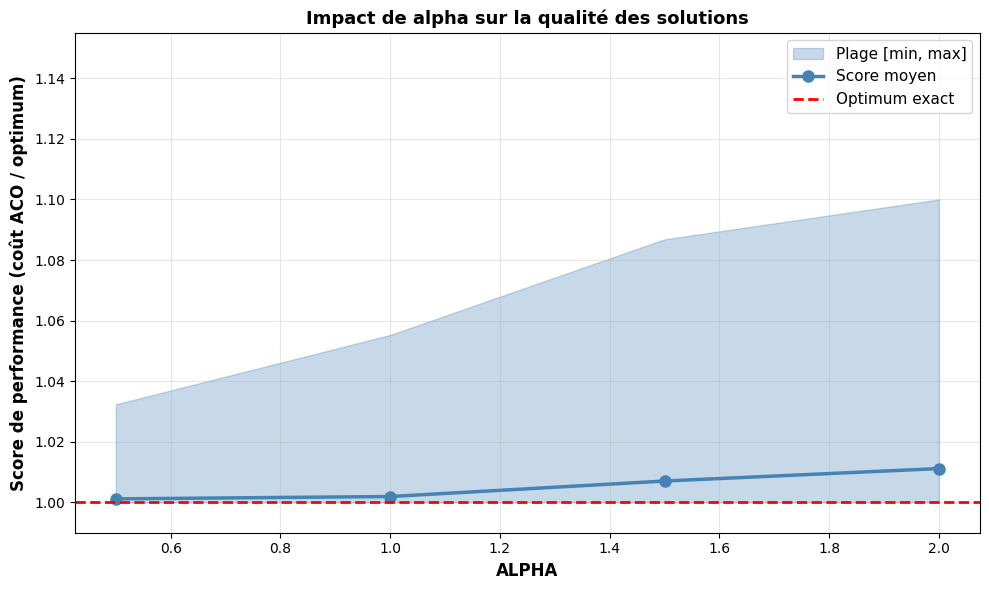

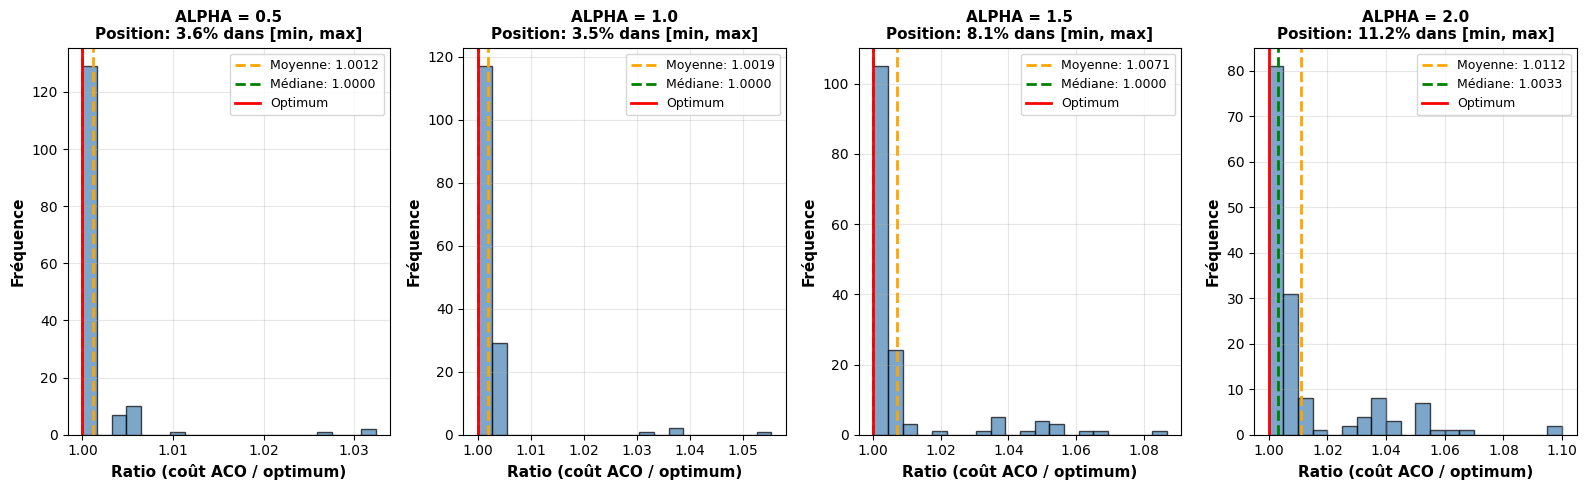

In [ ]:
print("="*60)
print("ÉTUDE DE SENSIBILITÉ : VARIATION DU PARAMÈTRE ALPHA")
print("="*60)
df_alpha, ratios_alpha = etude_sensibilite('alpha', alpha_values, instances, optima,
                                           fixed_params, n_exec=N_EXECUTIONS, verbose=True)
print("\nRésultats (alpha):\n")
afficher_resultats('alpha', df_alpha)
print("\n")
tracer_sensibilite('alpha', df_alpha, ratios_alpha)
tracer_distribution('alpha', df_alpha, ratios_alpha)

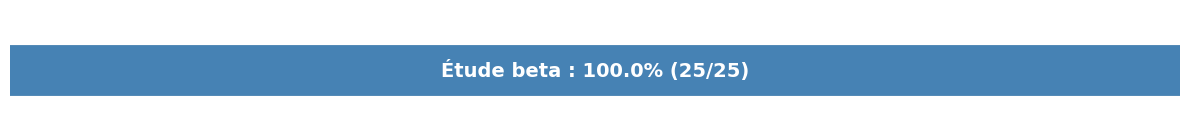


Résultats (beta):



,BETA,Score moyen,Médiane,Min,Max,Position (%),Coût moyen
0,1,1.0206,1.0101,1.0000,1.1084,19.0%,165825.0733
1,2,1.0009,1.0000,1.0000,1.0318,2.7%,162662.6333
2,3,1.0019,1.0000,1.0000,1.0511,3.6%,162808.2667
3,4,1.0038,1.0000,1.0000,1.0571,6.6%,163109.7733
4,5,1.0052,1.0000,1.0000,1.1000,5.2%,163313.2667


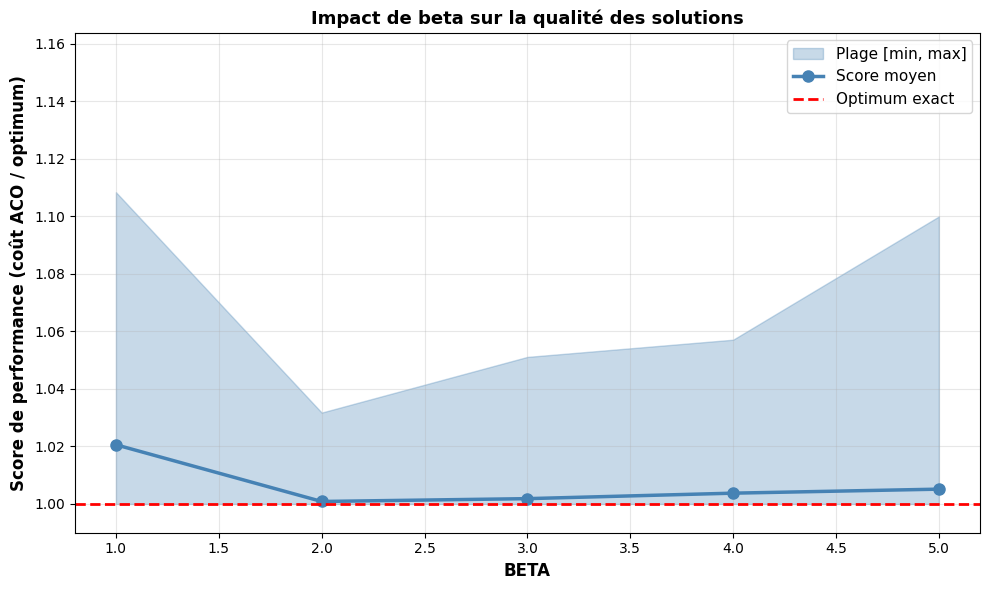

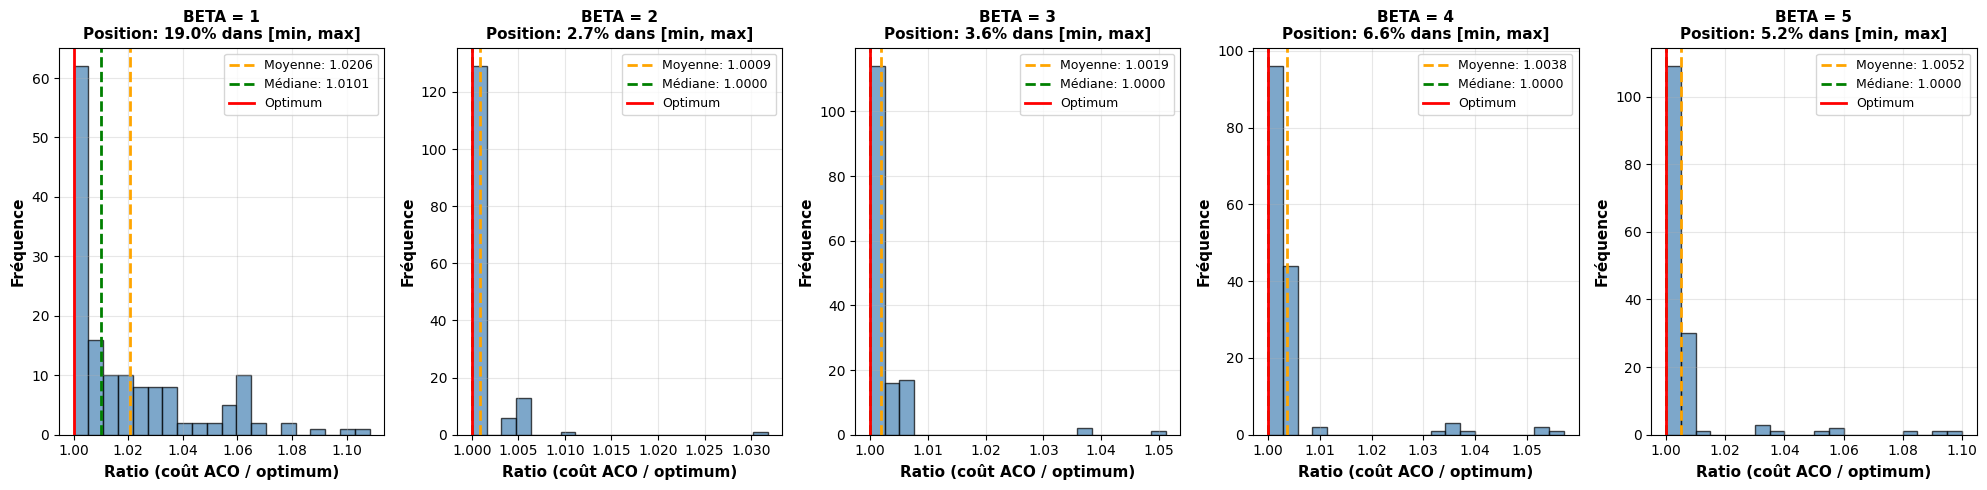

In [ ]:
print("="*60)
print("ÉTUDE DE SENSIBILITÉ : VARIATION DU PARAMÈTRE BETA")
print("="*60)
fixed_params['alpha'] = 1.0
df_beta, ratios_beta = etude_sensibilite('beta', beta_values, instances, optima,
                                        fixed_params, n_exec=N_EXECUTIONS, verbose=True)
print("\nRésultats (beta):\n")
afficher_resultats('beta', df_beta)
print("\n")
tracer_sensibilite('beta', df_beta, ratios_beta)
tracer_distribution('beta', df_beta, ratios_beta)

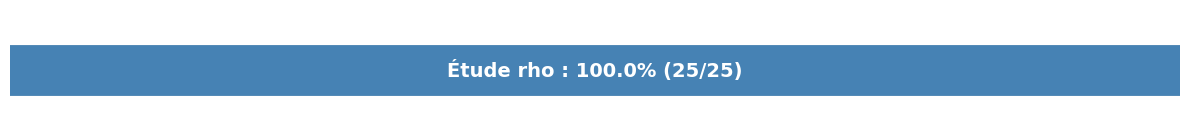


Résultats (rho):



,RHO,Score moyen,Médiane,Min,Max,Position (%),Coût moyen
0,0.100000,1.0016,1.0000,1.0000,1.0363,4.3%,162766.2000
1,0.200000,1.0043,1.0000,1.0000,1.0868,4.9%,163181.7200
2,0.300000,1.0101,1.0000,1.0000,1.1211,8.4%,164062.6867
3,0.400000,1.0102,1.0000,1.0000,1.1099,9.2%,164077.7800
4,0.500000,1.0125,1.0000,1.0000,1.1158,10.8%,164451.0600


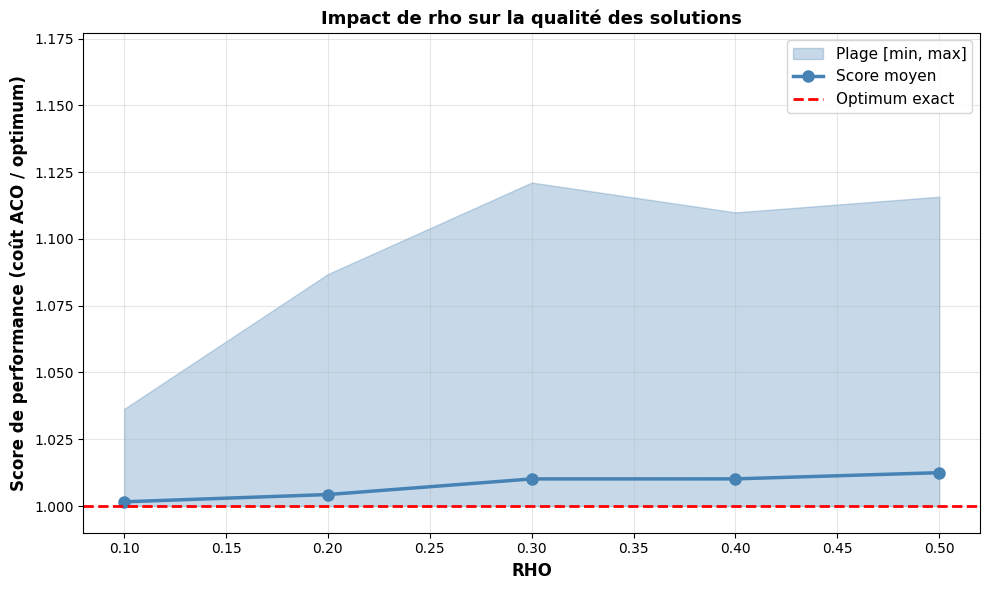

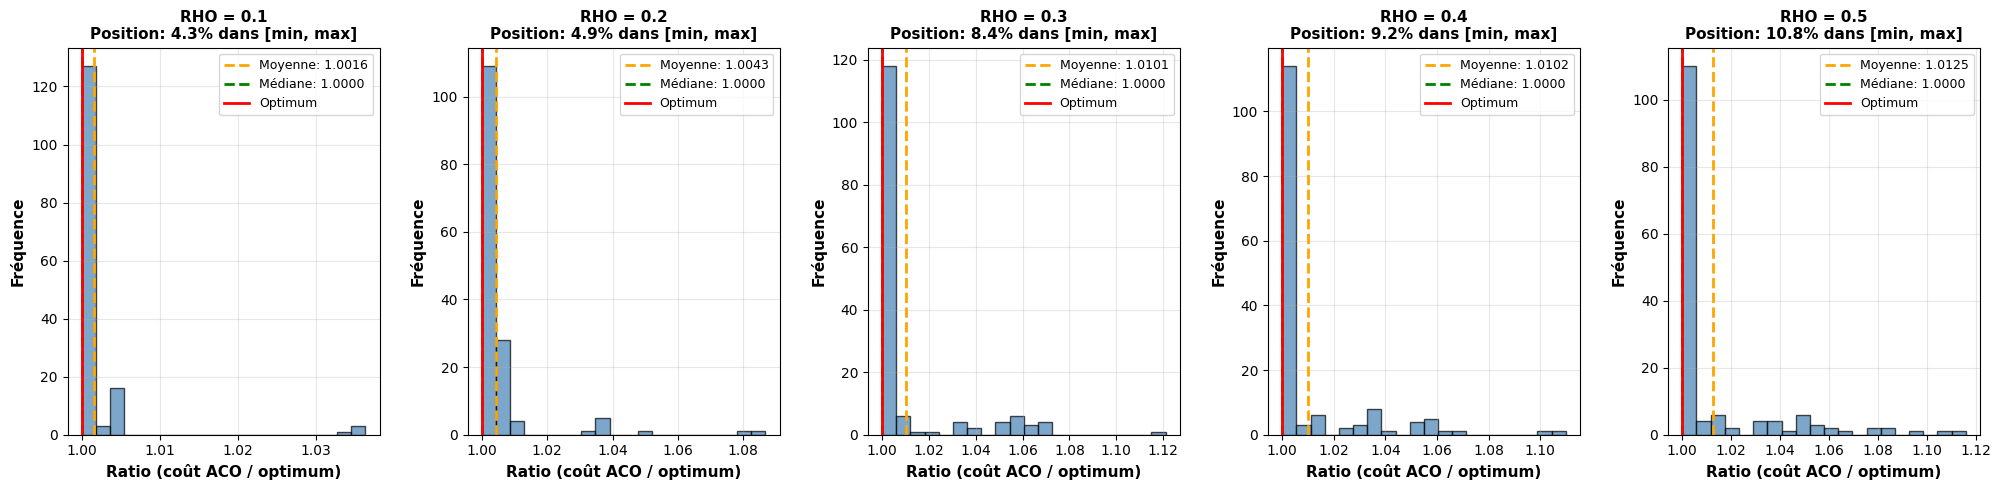

In [ ]:
print("="*60)
print("ÉTUDE DE SENSIBILITÉ : VARIATION DU PARAMÈTRE RHO")
print("="*60)
fixed_params['alpha'] = 1.0
fixed_params['beta'] = 3
df_rho, ratios_rho = etude_sensibilite('rho', rho_values, instances, optima,
                                       fixed_params, n_exec=N_EXECUTIONS, verbose=True)
print("\nRésultats (rho):\n")
afficher_resultats('rho', df_rho)
print("\n")
tracer_sensibilite('rho', df_rho, ratios_rho)
tracer_distribution('rho', df_rho, ratios_rho)

# Multi-Start : Configuration & Exécution personnalisée

In [ ]:
# ===== CONFIGURATION PERSONNALISÉE =====
# Modifiez ces paramètres avant d'exécuter la cellule suivante

# Taille du problème
CONFIG_N = 15                    # Nombre de villes (10, 15, 20, ...)
CONFIG_N_INSTANCES = 5           # Nombre d'instances à générer
CONFIG_N_EXECUTIONS = 30         # Nombre d'exécutions par configuration

# Paramètres ACO fixes
CONFIG_FIXED_PARAMS = {
    'alpha': 0.5,                # Influence des phéromones
    'beta': 3,                   # Influence de la visibilité
    'rho': 0.2,                  # Taux d'évaporation
    'nb_iterations': 50          # Nombre d'itérations ACO
}

print("Configuration personnalisée prête")
print(f"  Taille instances : n={CONFIG_N}")
print(f"  Instances : {CONFIG_N_INSTANCES} × {CONFIG_N_EXECUTIONS} exécutions")
print(f"  Itérations ACO : {CONFIG_FIXED_PARAMS['nb_iterations']}")

Configuration personnalisée prête
  Taille instances : n=15
  Instances : 5 × 30 exécutions
  Itérations ACO : 50


                         MULTI-START - PARAMÈTRES FIXES                         

Paramètres ACO :
  alpha           = 0.6
  beta            = 3
  rho             = 0.2
  nb_iterations   = 50
  Lancements     = 20

Instance TSP : n=15, optimum=182246

Lancement multi-start (N=20)...  

Résultats :
  Meilleur coût    :   182246
  Pire coût        :   182826
  Coût moyen       :   182391 (±258)
  Ratio moyen      : 1.0008
  Meilleur ratio   : 1.0000
  Temps total      : 5.99s

--- Détails des 20 lancements ---
 #   Coût  Ratio   Temps
 1 182246 1.0000 0.3100s
 2 182246 1.0000 0.2934s
 3 182246 1.0000 0.2950s
 4 182246 1.0000 0.3010s
 5 182826 1.0032 0.2996s
 6 182826 1.0032 0.2954s
 7 182246 1.0000 0.2947s
 8 182246 1.0000 0.2962s
 9 182246 1.0000 0.2956s
10 182246 1.0000 0.2957s
11 182246 1.0000 0.2963s
12 182246 1.0000 0.2963s
13 182246 1.0000 0.3151s
14 182246 1.0000 0.3065s
15 182246 1.0000 0.3036s
16 182826 1.0032 0.2987s
17 182826 1.0032 0.2992s
18 182246 1.0000 0.2992s
19 182826 1

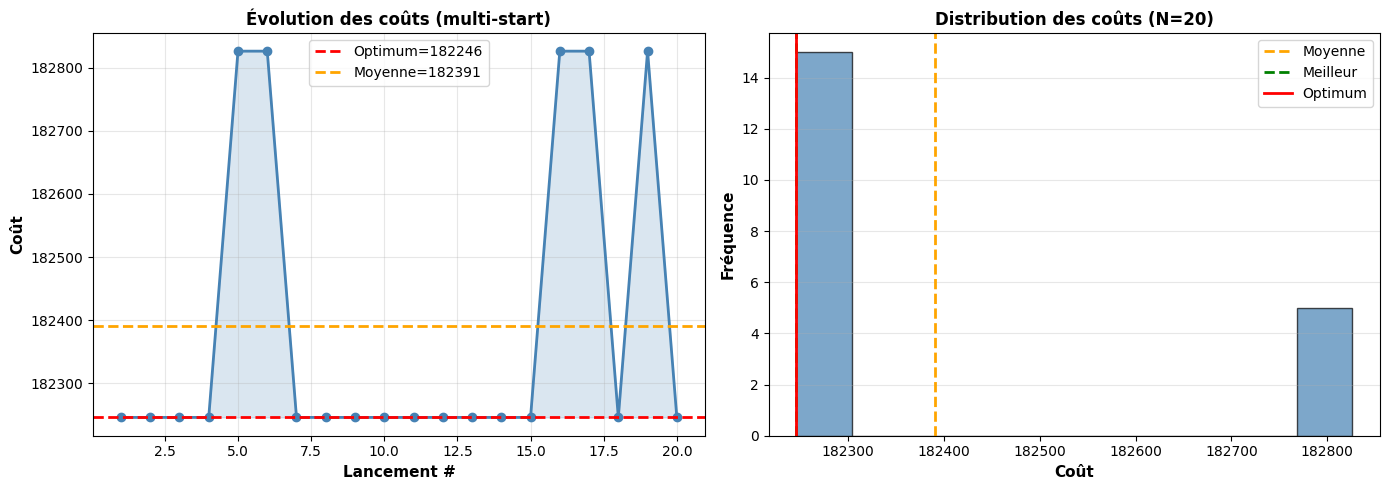

In [179]:
# ===== MULTI-START AVEC PARAMÈTRES FIXES =====

CONFIG_FIXED_PARAMS = {
    'alpha': 0.6,                # Influence des phéromones
    'beta': 3,                   # Influence de la visibilité
    'rho': 0.2,                  # Taux d'évaporation
    'nb_iterations': 50          # Nombre d'itérations ACO
}

MS_N_RUNS = 20  # Nombre de lancements
MS_INSTANCE_SEED = 999

print("="*80)
print("MULTI-START - PARAMÈTRES FIXES".center(80))
print("="*80)

print(f"\nParamètres ACO :")
for key, val in CONFIG_FIXED_PARAMS.items():
    print(f"  {key:15} = {val}")
print(f"  Lancements     = {MS_N_RUNS}")

# Génération instance
coords_ms, dist_ms = generer_instance(15, seed=MS_INSTANCE_SEED)
tournee_opt, cout_opt, _ = resoudre_tsp_plne(dist_ms)

print(f"\nInstance TSP : n=15, optimum={cout_opt:.0f}\n")
print(f"Lancement multi-start (N={MS_N_RUNS})...", end='', flush=True)

# Exécution multi-start
df_ms, stats_ms = multi_start_aco(dist_ms, cout_opt, CONFIG_FIXED_PARAMS, n_runs=MS_N_RUNS)

print("  \n")

# Résultats principaux
print(f"Résultats :")
print(f"  Meilleur coût    : {stats_ms['meilleur_cout']:8.0f}")
print(f"  Pire coût        : {stats_ms['pire_cout']:8.0f}")
print(f"  Coût moyen       : {stats_ms['cout_moyen']:8.0f} (±{stats_ms['cout_std']:.0f})")
print(f"  Ratio moyen      : {stats_ms['ratio_moyen']:.4f}")
print(f"  Meilleur ratio   : {stats_ms['ratio_min']:.4f}")
print(f"  Temps total      : {stats_ms['temps_total']:.2f}s")

# Tableau détaillé
print(f"\n--- Détails des {MS_N_RUNS} lancements ---")
df_affiche = df_ms[['run', 'cout', 'ratio', 'temps']].copy()
df_affiche['cout'] = df_affiche['cout'].apply(lambda x: f"{x:.0f}")
df_affiche['ratio'] = df_affiche['ratio'].apply(lambda x: f"{x:.4f}")
df_affiche['temps'] = df_affiche['temps'].apply(lambda x: f"{x:.4f}s")
df_affiche.columns = ['#', 'Coût', 'Ratio', 'Temps']
print(df_affiche.to_string(index=False))

# Visualisation
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Graphe 1 : évolution des coûts
ax1 = axes[0]
ax1.plot(df_ms['run'], df_ms['cout'], marker='o', linewidth=2, markersize=6, color='steelblue')
ax1.axhline(y=cout_opt, color='red', linestyle='--', linewidth=2, label=f'Optimum={cout_opt:.0f}')
ax1.axhline(y=stats_ms['cout_moyen'], color='orange', linestyle='--', linewidth=2, label=f'Moyenne={stats_ms["cout_moyen"]:.0f}')
ax1.fill_between(df_ms['run'], cout_opt, df_ms['cout'], alpha=0.2, color='steelblue')
ax1.set_xlabel('Lancement #', fontsize=11, fontweight='bold')
ax1.set_ylabel('Coût', fontsize=11, fontweight='bold')
ax1.set_title('Évolution des coûts (multi-start)', fontsize=12, fontweight='bold')
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.3)

# Graphe 2 : distribution des coûts
ax2 = axes[1]
ax2.hist(df_ms['cout'], bins=10, alpha=0.7, color='steelblue', edgecolor='black')
ax2.axvline(stats_ms['cout_moyen'], color='orange', linestyle='--', linewidth=2, label='Moyenne')
ax2.axvline(stats_ms['meilleur_cout'], color='green', linestyle='--', linewidth=2, label='Meilleur')
ax2.axvline(cout_opt, color='red', linestyle='-', linewidth=2, label='Optimum')
ax2.set_xlabel('Coût', fontsize=11, fontweight='bold')
ax2.set_ylabel('Fréquence', fontsize=11, fontweight='bold')
ax2.set_title(f'Distribution des coûts (N={MS_N_RUNS})', fontsize=12, fontweight='bold')
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()